# Лабораторная работа №1. Основы машинного обучения и предобработка данных

**ФИО:** Горюнова Алина  
**Номер зачётной книжки:** ИЦ-230453 
**Вариант задания:** 3 — Wine Quality (многоклассовая классификация, определение качества вина)

**Источник данных:** UCI ML Repository, ID 186 — https://archive.ics.uci.edu/dataset/186/wine+quality, лицензия CC BY 4.0.

## Цель работы
Получить практический опыт предобработки данных, обучения базовых моделей машинного обучения и оценки их качества на реальном датасете.

## Параметры варианта 3
| Параметр | Значение |
|---|---|
| Тип задачи | многоклассовая классификация |
| `random_state` / seed | 3 |
| Модели | логистическая регрессия, KNN (k = 3 + 2 = 5), наивный Байес |
| GridSearchCV | 3 комбинации гиперпараметров |
| Кросс-валидация | cv = 5 (StratifiedKFold) |
| Вопросы для ответа | интерпретация классов и рекомендации |

## План работы
1. Загрузка данных и первичный анализ
2. Формирование целевой переменной, новые признаки, пайплайн предобработки
3. Разбиение на train/test и EDA (только по обучающей выборке)
4. Обучение трёх моделей, кросс-валидация
5. Подбор гиперпараметров (GridSearchCV), сводная таблица и выбор лучшей модели
6. Анализ лучшей модели: важность признаков, ROC, ошибки, устойчивость
7. Бонус: ансамблевые модели и абляция признаков
8. Выводы

## 0. Окружение и воспроизводимость

In [1]:
import os
import random
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import chi2_contingency

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve, auc,
                             confusion_matrix, classification_report, recall_score)

# Номер варианта и seed (фиксируем до любых случайных операций)
VARIANT = 3
SEED = VARIANT
random.seed(SEED)
np.random.seed(SEED)

# Единые настройки графиков
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Версии библиотек (должны совпадать с requirements.txt)
print('numpy       ', np.__version__)
print('pandas      ', pd.__version__)
print('scikit-learn', sklearn.__version__)
print('scipy       ', scipy.__version__)
import matplotlib
print('matplotlib  ', matplotlib.__version__)

numpy        2.5.3
pandas       3.0.6
scikit-learn 1.9.1
scipy        1.18.1
matplotlib   3.11.2


## 1. Загрузка данных

Датасет состоит из двух файлов: красное (`winequality-red.csv`, 1599 образцов) и белое (`winequality-white.csv`, 4898 образцов) вино португальского Vinho Verde. Скачиваем архив с UCI **один раз**, дальше работаем офлайн. Папка `data/` добавлена в `.gitignore`, данные в репозиторий не коммитятся.

Оба файла объединяются в одну таблицу, а тип вина сохраняется в категориальном признаке `wine_type` (red/white) — он понадобится для кодирования категорий.

In [2]:
DATA_DIR = 'data'
URL = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
RED_PATH = os.path.join(DATA_DIR, 'winequality-red.csv')
WHITE_PATH = os.path.join(DATA_DIR, 'winequality-white.csv')

def download_data():
    """Скачивает архив с UCI и распаковывает csv (если файлов ещё нет)."""
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists(RED_PATH) and os.path.exists(WHITE_PATH):
        print('Файлы уже скачаны, повторная загрузка не нужна')
        return
    zip_path = os.path.join(DATA_DIR, 'wine_quality.zip')
    # UCI иногда режет запросы без User-Agent, поэтому добавляем заголовок
    req = urllib.request.Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
    try:
        with urllib.request.urlopen(req, timeout=60) as resp, open(zip_path, 'wb') as f:
            f.write(resp.read())
    except Exception as e:
        raise RuntimeError(
            f'Не удалось скачать данные ({e}). Скачайте архив вручную по ссылке {URL} '
            f'и положите winequality-red.csv и winequality-white.csv в папку {DATA_DIR}/'
        )
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    print('Данные скачаны и распакованы')

download_data()

def load_data():
    red = pd.read_csv(RED_PATH, sep=';')
    white = pd.read_csv(WHITE_PATH, sep=';')
    red['wine_type'] = 'red'
    white['wine_type'] = 'white'
    data = pd.concat([red, white], ignore_index=True)
    # пробелы в названиях колонок неудобны, заменяем на подчёркивания
    data.columns = [c.replace(' ', '_') for c in data.columns]
    return data

df = load_data()
print('Размер данных:', df.shape)
df.head()

Файлы уже скачаны, повторная загрузка не нужна
Размер данных: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Первичный анализ данных

In [3]:
print('Пропущенные значения:')
print(df.isnull().sum())
print()
print('Типы данных:')
print(df.dtypes)
print()
print('Полных дубликатов строк:', df.duplicated().sum())
df.describe().T

Пропущенные значения:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Типы данных:
fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
dtype: object

Полных дубликатов строк: 1177


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Пропусков в данных нет, но в пайплайн всё равно включаем `SimpleImputer` (медиана для числовых, мода для категориальных), чтобы решение работало и на данных с пропусками.

Обнаружено много полностью совпадающих строк. Это не ошибка, а особенность датасета: разные вина с одинаковым химическим составом получили одинаковые оценки. Но если оставить дубликаты, одна и та же строка может попасть и в train, и в test — тогда оценка на тесте будет завышена (утечка через дубли). Поэтому дубликаты удаляем **до** разбиения. Это операция над строками, статистик по данным она не вычисляет, так что на утечку при предобработке не влияет.

In [4]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Удалено дубликатов: {n_before - len(df)}, осталось строк: {len(df)}')
print()
print('Распределение исходной оценки quality:')
print(df['quality'].value_counts().sort_index())

Удалено дубликатов: 1177, осталось строк: 5320

Распределение исходной оценки quality:
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


**Интерпретация.** Датасет содержит 6497 образцов (1599 красных и 4898 белых вин), 11 химических признаков и оценку `quality`. Пропусков нет. Полных дубликатов оказалось 1177 (около 18 %), после их удаления осталось 5320 объектов. Оценки распределены неравномерно: основная масса вин получила 5–6 баллов, а крайние оценки 3 и 9 встречаются 30 и 5 раз, поэтому в следующем разделе они объединяются с соседними.

## 3. Целевая переменная

Исходная оценка `quality` принимает значения от 3 до 9, но крайние классы очень малочисленны (оценка 9 встречается всего несколько раз). Для стратифицированного разбиения и 5-fold кросс-валидации в каждом классе должно быть хотя бы по 5 объектов, иначе фолды получаются без этого класса. Поэтому крайние классы объединяем:

* `quality ≤ 4` → класс **4**
* `quality = 5, 6, 7` → классы 5, 6, 7 без изменений
* `quality ≥ 8` → класс **8**

Получается 5 упорядоченных классов. Задача остаётся многоклассовой, порядок классов сохраняется.

In [5]:
TARGET = 'quality_class'
df[TARGET] = df['quality'].clip(lower=4, upper=8)

# исходную quality из признаков убираем: иначе она утечёт в модель
X = df.drop(columns=['quality', TARGET])
y = df[TARGET]

print(y.value_counts().sort_index())
print()
print('Доли классов:')
print((y.value_counts(normalize=True).sort_index() * 100).round(1).astype(str) + ' %')

quality_class
4     236
5    1752
6    2323
7     856
8     153
Name: count, dtype: int64

Доли классов:
quality_class
4     4.4 %
5    32.9 %
6    43.7 %
7    16.1 %
8     2.9 %
Name: proportion, dtype: str


## 4. Новые признаки, выбросы и пайплайн предобработки

Чтобы ничего не «подглядывало» в тестовую выборку, вся предобработка оформлена как `Pipeline` из sklearn-трансформеров: `fit` вызывается только на обучающей выборке, а к тестовой применяется только `transform`. В кросс-валидации пайплайн переобучается на каждом фолде заново.

**Новые признаки (3 штуки)** — вычисляются построчно, поэтому не используют статистики других объектов:

1. `total_acidity` = fixed + volatile + citric acid — суммарная кислотность. Вкус вина зависит от общего кислотного баланса, а не только от отдельных кислот.
2. `free_so2_share` = free SO₂ / total SO₂ — доля свободного диоксида серы. Именно свободный SO₂ работает как консервант, а доля показывает, сколько его осталось от общего количества.
3. `sugar_acid_ratio` = residual sugar / total_acidity — баланс сладости и кислотности (ощущение «сладкое/кислое»).

**Выбросы.** Обрабатываем методом IQR-винзоризации: значения за пределами `[Q1 − k·IQR, Q3 + k·IQR]` обрезаются до границ. Строки не удаляем — у нас и так мало объектов крайних классов, а выбросы в химических показателях часто настоящие (редкие вина), а не ошибки измерения. Берём k = 3 (только «сильные» выбросы), потому что многие признаки (`chlorides`, `residual_sugar`) имеют естественный тяжёлый правый хвост, и при k = 1.5 пришлось бы обрезать слишком много нормальных значений. Границы считаются **только по обучающей выборке** (внутри `fit` трансформера).

**Масштабирование:** `StandardScaler` (нужен для KNN и логистической регрессии, для наивного Байеса не мешает).  
**Категории:** `wine_type` → `OneHotEncoder` (признак номинальный, порядка нет; `drop='if_binary'` оставляет один столбец, чтобы не было коллинеарности).

In [6]:
class WineFeatureAdder(TransformerMixin, BaseEstimator):
    """Добавляет три новых признака. Формулы построчные, ничего не обучается."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['total_acidity'] = X['fixed_acidity'] + X['volatile_acidity'] + X['citric_acid']
        # clip, чтобы не делить на ноль
        X['free_so2_share'] = X['free_sulfur_dioxide'] / X['total_sulfur_dioxide'].clip(lower=1)
        X['sugar_acid_ratio'] = X['residual_sugar'] / X['total_acidity'].clip(lower=0.1)
        return X


class IQRClipper(TransformerMixin, BaseEstimator):
    """Обрезает выбросы по правилу IQR. Границы считаются в fit (то есть только по train)."""

    def __init__(self, k=3.0):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1 = np.nanpercentile(X, 25, axis=0)
        q3 = np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.k * iqr
        self.upper_ = q3 + self.k * iqr
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


BASE_NUMERIC = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
                'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
                'pH', 'sulphates', 'alcohol']
NEW_FEATURES = ['total_acidity', 'free_so2_share', 'sugar_acid_ratio']
numeric_cols = BASE_NUMERIC + NEW_FEATURES
categorical_cols = ['wine_type']


def build_preprocessor(num_cols, cat_cols):
    """Собирает полный препроцессор: новые признаки -> (выбросы, пропуски, масштаб) + one-hot."""
    numeric_transformer = Pipeline(steps=[
        ('clip', IQRClipper(k=3.0)),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)),
    ])
    columns = ColumnTransformer(
        transformers=[('num', numeric_transformer, num_cols),
                      ('cat', categorical_transformer, cat_cols)],
        verbose_feature_names_out=False,
    )
    return Pipeline(steps=[('features', WineFeatureAdder()), ('columns', columns)])


preprocessor = build_preprocessor(numeric_cols, categorical_cols)
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}_

## 5. Разбиение на обучающую и тестовую выборки

Разбиваем **до** любой предобработки: 80 % / 20 %, `random_state = 3` (номер варианта), со стратификацией по классам (классы несбалансированы, поэтому доли должны сохраниться).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('train:', X_train.shape, ' test:', X_test.shape)

# проверим, что пропорции классов сохранились
check = pd.DataFrame({
    'train, %': (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    'test, %': (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
})
check

train: (4256, 12)  test: (1064, 12)


,"train, %","test, %"
quality_class,,
4,4.4,4.4
5,32.9,32.9
6,43.7,43.7
7,16.1,16.1
8,2.9,2.9


## 6. Разведочный анализ данных (EDA)

Весь EDA выполняется только на **обучающей** выборке, чтобы выводы (например, о выбросах) не опирались на тест.

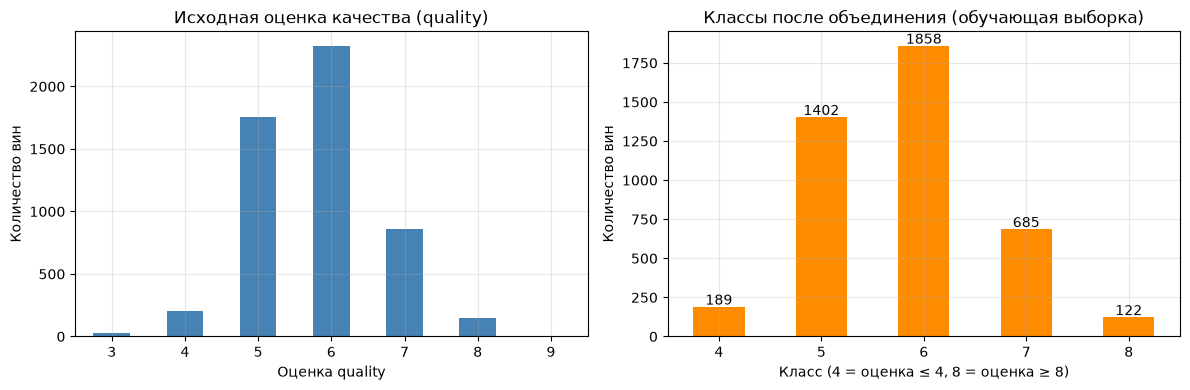

In [8]:
# обучающая выборка с новыми признаками и целевой переменной (для EDA)
train_eda = WineFeatureAdder().transform(X_train)
train_eda[TARGET] = y_train

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# слева — исходная оценка (по всем данным после удаления дубликатов), справа — итоговые классы на train
df['quality'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Исходная оценка качества (quality)')
axes[0].set_xlabel('Оценка quality')
axes[0].set_ylabel('Количество вин')
axes[0].tick_params(axis='x', rotation=0)

counts = y_train.value_counts().sort_index()
counts.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Классы после объединения (обучающая выборка)')
axes[1].set_xlabel('Класс (4 = оценка ≤ 4, 8 = оценка ≥ 8)')
axes[1].set_ylabel('Количество вин')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 15, str(v), ha='center')

plt.tight_layout()
plt.show()

**Интерпретация.** Распределение оценок колоколообразное и сильно смещено к «средним» оценкам: на классы 5 и 6 приходится около 77 % обучающей выборки (32.9 % и 43.7 %), на редкие классы 4 и 8 — всего 4.4 % и 2.9 %. Из этого следуют два вывода:
* наивный классификатор, всегда предсказывающий класс 6, уже даёт accuracy ≈ 0.44, и любую модель нужно сравнивать с этим значением, а не с нулём;
* accuracy плохо отражает качество на редких классах, поэтому дополнительно используются F1 weighted, F1 macro и ROC-AUC.

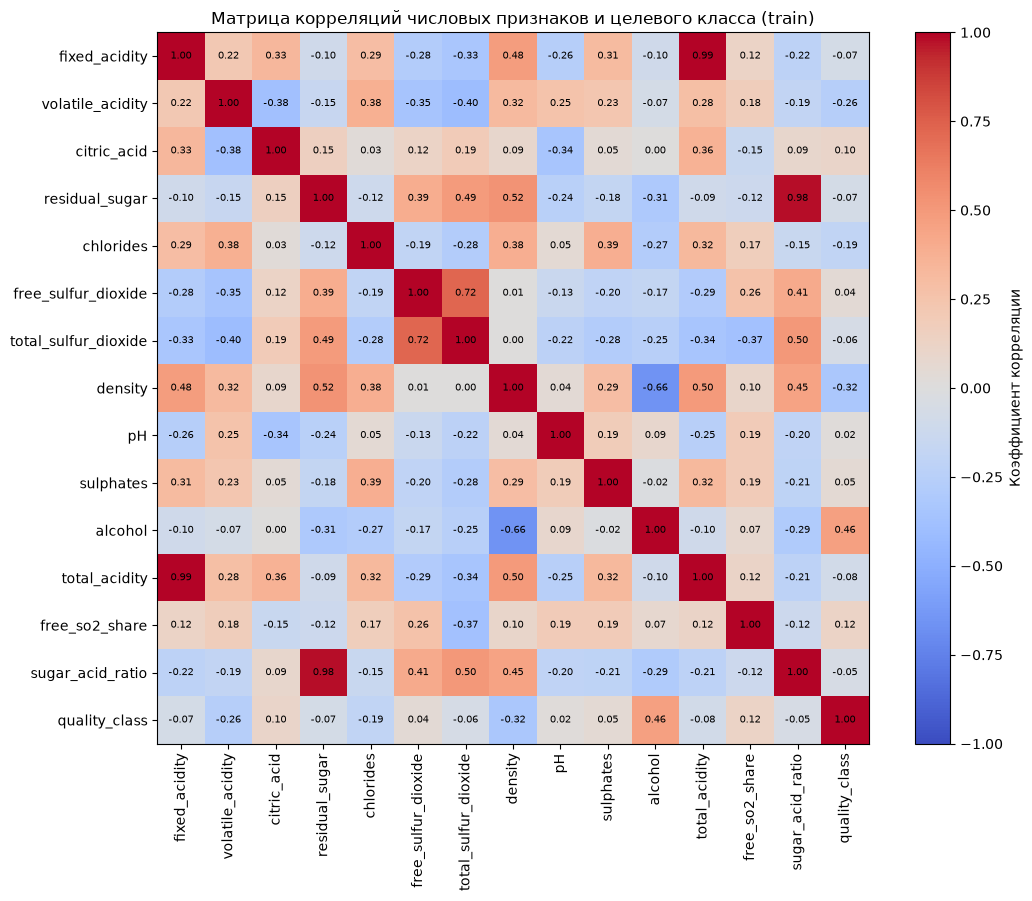

Корреляция признаков с целевым классом (по модулю, по убыванию):
alcohol                 0.462
density                -0.321
volatile_acidity       -0.261
chlorides              -0.193
free_so2_share          0.120
citric_acid             0.103
total_acidity          -0.082
residual_sugar         -0.066
fixed_acidity          -0.066
total_sulfur_dioxide   -0.056
sugar_acid_ratio       -0.053
sulphates               0.048
free_sulfur_dioxide     0.044
pH                      0.021
Name: quality_class, dtype: float64


In [9]:
# матрица корреляций (Пирсон) для числовых признаков и целевого класса
corr_cols = numeric_cols + [TARGET]
corr = train_eda[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
ax.set_title('Матрица корреляций числовых признаков и целевого класса (train)')
ax.grid(False)
plt.colorbar(im, ax=ax, label='Коэффициент корреляции')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевым классом (по модулю, по убыванию):')
print(corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).round(3))

**Интерпретация.**
* С целевым классом линейно связаны немногие признаки: `alcohol` (r = +0.46), `density` (−0.32), `volatile_acidity` (−0.26), `chlorides` (−0.19). Связи умеренные, поэтому высокого качества от моделей ждать не стоит.
* Содержание алкоголя — самый сильный положительный фактор, летучая кислотность (запах уксуса) и хлориды влияют отрицательно.
* Признаки зависят друг от друга: `alcohol` и `density` связаны с r = −0.66 (спирт легче воды), `density` и `residual_sugar` — +0.52, `free_sulfur_dioxide` и `total_sulfur_dioxide` — +0.72. Значит, вклад признаков будет «делиться» между коррелированными, а наивный Байес с допущением о независимости признаков окажется в невыгодном положении.
* Созданные признаки `total_acidity` и `sugar_acid_ratio` почти дублируют исходные (r = 0.99 с `fixed_acidity` и 0.98 с `residual_sugar`), а `free_so2_share` несёт новую информацию (r с классом +0.12, при том что у его компонентов 0.04 и −0.06).

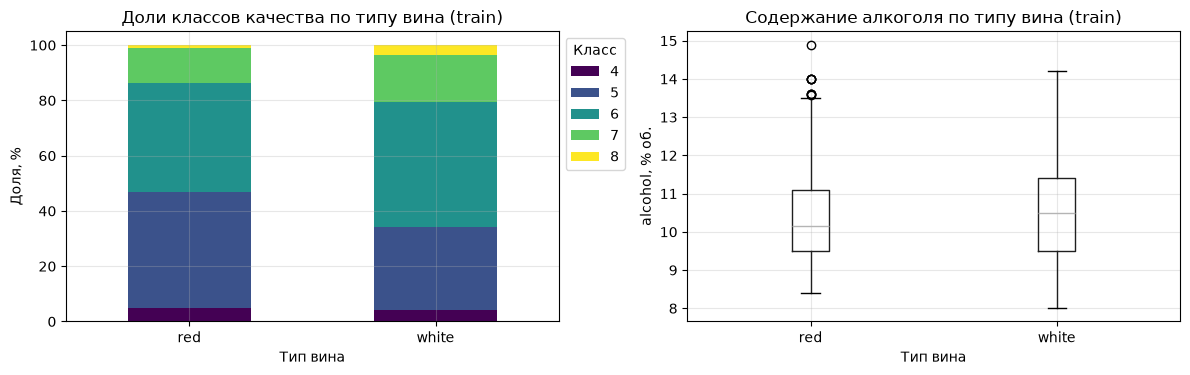

quality_class    4    5     6    7    8
wine_type                              
red             53  459   431  138   13
white          136  943  1427  547  109

Хи-квадрат = 68.53, p-value = 4.63e-14, V Крамера = 0.127
Средний класс качества:
wine_type
red      5.633
white    5.858
Name: quality_class, dtype: float64


In [10]:
# влияние категориального признака wine_type на целевую переменную
ct = pd.crosstab(X_train['wine_type'], y_train)
share = ct.div(ct.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
share.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('Доли классов качества по типу вина (train)')
axes[0].set_xlabel('Тип вина')
axes[0].set_ylabel('Доля, %')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Класс', bbox_to_anchor=(1.0, 1.0))

train_eda.boxplot(column='alcohol', by='wine_type', ax=axes[1])
axes[1].set_title('Содержание алкоголя по типу вина (train)')
axes[1].set_xlabel('Тип вина')
axes[1].set_ylabel('alcohol, % об.')
fig.suptitle('')
plt.tight_layout()
plt.show()

print(ct)
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f'\nХи-квадрат = {chi2:.2f}, p-value = {p:.2e}, V Крамера = {cramers_v:.3f}')
print('Средний класс качества:')
print(train_eda.groupby('wine_type')[TARGET].mean().round(3))

**Интерпретация.** В красных винах чаще встречается класс 5 (42.0 % против 29.8 % у белых), в белых — классы 6, 7 и 8 (45.1 %, 17.3 %, 3.4 % против 39.4 %, 12.6 %, 1.2 %). Средний класс у белых вин выше (5.86 против 5.63). Критерий хи-квадрат даёт p ≈ 5·10⁻¹⁴, то есть связь значима статистически, но V Крамера = 0.127 — эффект слабый. Тип вина полезен как дополнительный признак, но главным фактором качества не является.

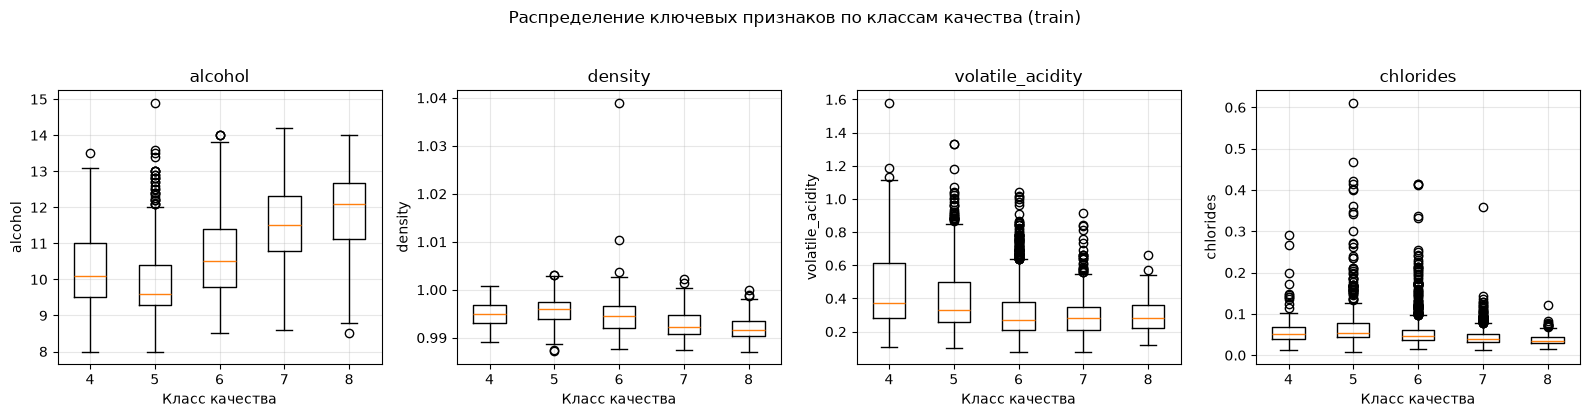

In [11]:
# влияние самых «сильных» числовых признаков на класс качества
top_feats = ['alcohol', 'density', 'volatile_acidity', 'chlorides']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
classes_sorted = sorted(y_train.unique())
for ax, col in zip(axes, top_feats):
    data_by_class = [train_eda.loc[train_eda[TARGET] == c, col] for c in classes_sorted]
    ax.boxplot(data_by_class, tick_labels=classes_sorted)
    ax.set_title(col)
    ax.set_xlabel('Класс качества')
    ax.set_ylabel(col)
fig.suptitle('Распределение ключевых признаков по классам качества (train)', y=1.03)
plt.tight_layout()
plt.show()

**Интерпретация.** Медиана алкоголя растёт с ростом качества: 9.6 % (класс 5), 10.5 % (6), 11.5 % (7), 12.1 % (8). Медиана летучей кислотности у классов 4 и 5 выше (0.37 и 0.33), чем у классов 6–8 (0.27–0.28). Медиана хлоридов, наоборот, убывает с ростом качества (с 0.053 у класса 5 до 0.035 у класса 8). Класс 4 выбивается из монотонности по алкоголю (медиана 10.1 % выше, чем у класса 5): дефектные вина отличаются не низким алкоголем, а повышенной летучей кислотностью (и, по медианам train, низким свободным SO₂: 15 против 27–31 у остальных классов). Ящики соседних классов сильно перекрываются, поэтому полностью разделить классы по этим признакам нельзя.

### Выбросы

Сначала посмотрим, сколько значений выходит за границы IQR при разных k — по обучающей выборке.

                      k = 1.5  k = 3.0  k = 1.5, %  k = 3.0, %
fixed_acidity             252       63         5.9         1.5
volatile_acidity          227       32         5.3         0.8
citric_acid               113        7         2.7         0.2
residual_sugar            113        2         2.7         0.0
chlorides                 193       95         4.5         2.2
free_sulfur_dioxide        38        7         0.9         0.2
total_sulfur_dioxide        9        1         0.2         0.0
density                     2        1         0.0         0.0
pH                         41        1         1.0         0.0
sulphates                 127       23         3.0         0.5
alcohol                     1        0         0.0         0.0
total_acidity             235       58         5.5         1.4
free_so2_share            130        6         3.1         0.1
sugar_acid_ratio          108        4         2.5         0.1


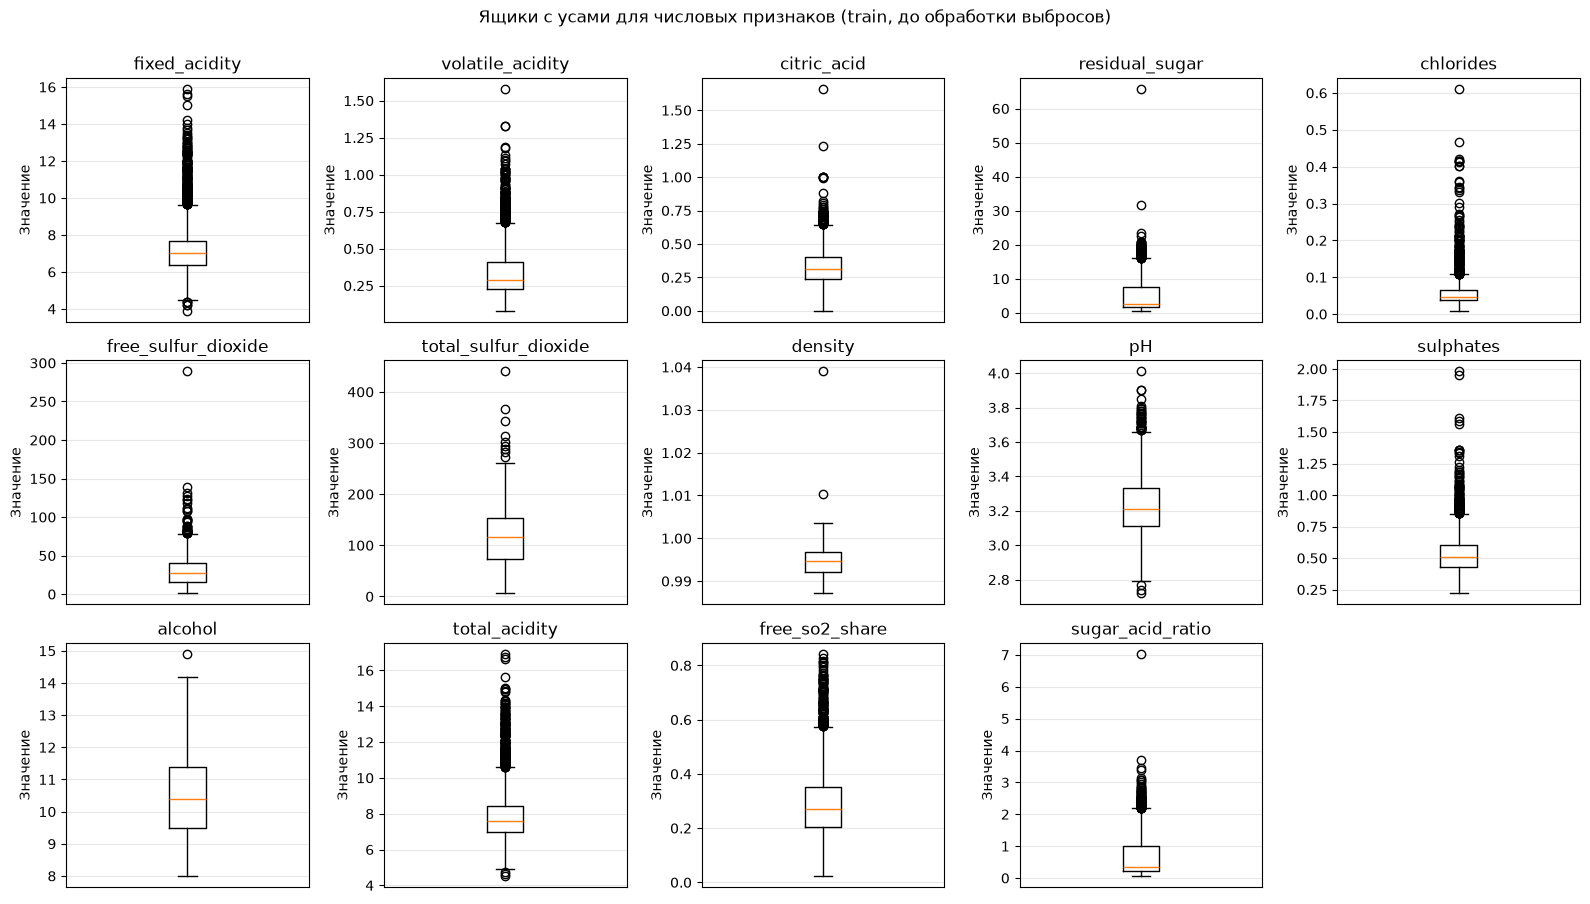

In [12]:
def count_outliers(series, k):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - k * iqr) | (series > q3 + k * iqr)).sum())

out_table = pd.DataFrame({
    'k = 1.5': [count_outliers(train_eda[c], 1.5) for c in numeric_cols],
    'k = 3.0': [count_outliers(train_eda[c], 3.0) for c in numeric_cols],
}, index=numeric_cols)
out_table['k = 1.5, %'] = (out_table['k = 1.5'] / len(train_eda) * 100).round(1)
out_table['k = 3.0, %'] = (out_table['k = 3.0'] / len(train_eda) * 100).round(1)
print(out_table)

fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.boxplot(train_eda[col])
    ax.set_title(col)
    ax.set_xticks([])
    ax.set_ylabel('Значение')
for ax in axes.ravel()[len(numeric_cols):]:
    ax.set_visible(False)
fig.suptitle('Ящики с усами для числовых признаков (train, до обработки выбросов)', y=1.0)
plt.tight_layout()
plt.show()

**Интерпретация.** При k = 1.5 за границы выходит до 5–6 % значений в `fixed_acidity`, `volatile_acidity`, `total_acidity`, `chlorides`. Это слишком много для «ошибок измерения»: распределения просто скошены вправо, а ящики показывают длинные хвосты. При k = 3 «сильных» выбросов остаётся мало (больше всего в `chlorides` — 2.2 %, `fixed_acidity` — 1.5 %). Поэтому для обработки выбран метод винзоризации по IQR с k = 3 (обрезка до границ, без удаления строк): строки не теряются (важно для редких классов), а экстремальные значения не искажают масштабирование и работу KNN и логистической регрессии. Границы считаются по обучающей выборке; в итоге обрезано 0.50 % значений в train и 0.41 % в test.

## 7. Проверка предобработки (отсутствие утечки)

In [13]:
# fit только на train, к test — только transform
prep_demo = clone(preprocessor)
Xtr_p = prep_demo.fit_transform(X_train)
Xte_p = prep_demo.transform(X_test)
feature_names = prep_demo.named_steps['columns'].get_feature_names_out()
print('Признаков после предобработки:', len(feature_names))
print(list(feature_names))

stats = pd.DataFrame({
    'train mean': Xtr_p.mean(axis=0),
    'train std': Xtr_p.std(axis=0),
    'test mean': Xte_p.mean(axis=0),
    'test std': Xte_p.std(axis=0),
}, index=feature_names).round(3)
print(stats)

# сколько значений было обрезано на train и на test (границы — по train)
clipper = prep_demo.named_steps['columns'].named_transformers_['num'].named_steps['clip']
tr_raw = WineFeatureAdder().transform(X_train)[numeric_cols].values
te_raw = WineFeatureAdder().transform(X_test)[numeric_cols].values
clip_tr = ((tr_raw < clipper.lower_) | (tr_raw > clipper.upper_)).sum()
clip_te = ((te_raw < clipper.lower_) | (te_raw > clipper.upper_)).sum()
print(f'\nОбрезано значений: train — {clip_tr} ({clip_tr / tr_raw.size * 100:.2f} %), '
      f'test — {clip_te} ({clip_te / te_raw.size * 100:.2f} %)')

Признаков после предобработки: 15
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'total_acidity', 'free_so2_share', 'sugar_acid_ratio', 'wine_type_white']
                      train mean  train std  test mean  test std
fixed_acidity              0.000      1.000     -0.044     0.953
volatile_acidity          -0.000      1.000      0.009     0.964
citric_acid               -0.000      1.000     -0.047     1.013
residual_sugar             0.000      1.000      0.008     0.990
chlorides                 -0.000      1.000     -0.016     0.989
free_sulfur_dioxide        0.000      1.000     -0.003     0.965
total_sulfur_dioxide      -0.000      1.000      0.027     1.011
density                   -0.000      1.000     -0.029     0.958
pH                         0.000      1.000      0.014     1.007
sulphates                  0.000      1.000      0.054     1.001
alcoh

**Интерпретация.** На обучающей выборке после масштабирования среднее равно 0, а стандартное отклонение равно 1. На тестовой выборке они немного отличаются (например, среднее `sulphates` = 0.054, `citric_acid` = −0.047, std от 0.95 до 1.01) — это ожидаемо и правильно: параметры масштаба получены только по train, а к тесту применён лишь `transform`, то есть тест не «подгонялся» под нулевое среднее. Доля белых вин одинакова в обеих частях (74.3 % и 75.1 %) благодаря стратификации. Итого после предобработки получается 15 признаков (11 исходных, 3 новых и один бинарный `wine_type_white`).

## 8. Обучение базовых моделей

Три модели обучаются на **одном и том же** разбиении (train/test выше), каждая внутри пайплайна `препроцессор → модель`. Параметры варианта: KNN с `k = VARIANT + 2 = 5`.

**Метрики для многоклассовой задачи с дисбалансом классов:**
* Accuracy — для общей картины (при дисбалансе сама по себе вводит в заблуждение);
* F1 weighted — основная метрика (учитывает размер классов), по ней же идёт кросс-валидация и подбор гиперпараметров;
* F1 macro — все классы равноправны, показывает качество на редких классах;
* ROC-AUC (one-vs-rest, macro) — качество ранжирования по вероятностям.

**Кросс-валидация:** `cv = 5`, стратифицированная (`StratifiedKFold(n_splits=5, shuffle=True, random_state=3)`), считается на обучающей выборке. Препроцессор внутри пайплайна переобучается на каждом фолде.

In [14]:
def make_pipe(model):
    """Пайплайн: свежая копия препроцессора + модель."""
    return Pipeline(steps=[('prep', clone(preprocessor)), ('model', model)])


def evaluate(pipe, X_, y_):
    """Метрики на выбранной выборке для уже обученного пайплайна."""
    pred = pipe.predict(X_)
    proba = pipe.predict_proba(X_)
    return {
        'Accuracy': accuracy_score(y_, pred),
        'F1 weighted': f1_score(y_, pred, average='weighted'),
        'F1 macro': f1_score(y_, pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_, proba, multi_class='ovr', labels=pipe.classes_),
    }


# кросс-валидация cv=5 (одинаковые фолды для всех моделей, т.к. фиксирован random_state)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scoring = {'accuracy': 'accuracy', 'f1_weighted': 'f1_weighted',
              'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc_ovr'}

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=VARIANT + 2),
    'Naive Bayes': GaussianNB(),
}

baseline_pipes, baseline_test, baseline_cv = {}, {}, {}
for name, model in baseline_models.items():
    pipe = make_pipe(model)
    pipe.fit(X_train, y_train)                       # обучение на train
    baseline_pipes[name] = pipe
    baseline_test[name] = evaluate(pipe, X_test, y_test)   # предсказания на test
    baseline_cv[name] = cross_validate(make_pipe(model), X_train, y_train,
                                       cv=cv, scoring=cv_scoring)

rows = []
for name in baseline_models:
    r = dict(baseline_test[name])
    r['CV F1 weighted (mean)'] = baseline_cv[name]['test_f1_weighted'].mean()
    r['CV F1 weighted (std)'] = baseline_cv[name]['test_f1_weighted'].std()
    r['CV Accuracy (mean)'] = baseline_cv[name]['test_accuracy'].mean()
    r['CV F1 macro (mean)'] = baseline_cv[name]['test_f1_macro'].mean()
    r['CV ROC-AUC (mean)'] = baseline_cv[name]['test_roc_auc'].mean()
    rows.append(pd.Series(r, name=name))
baseline_df = pd.DataFrame(rows)
print('Базовые модели (метрики на test + кросс-валидация cv=5 на train):')
baseline_df.round(4)

Базовые модели (метрики на test + кросс-валидация cv=5 на train):


,Accuracy,F1 weighted,F1 macro,ROC-AUC,CV F1 weighted (mean),CV F1 weighted (std),CV Accuracy (mean),CV F1 macro (mean),CV ROC-AUC (mean)
Logistic Regression,0.5686,0.5433,0.3564,0.8144,0.5078,0.0144,0.5383,0.3099,0.7583
KNN,0.5320,0.5161,0.3463,0.7227,0.4889,0.0133,0.5021,0.3424,0.6770
Naive Bayes,0.4314,0.4403,0.3440,0.7336,0.4234,0.0085,0.4159,0.3126,0.7003


**Интерпретация.**
* Лучшая из базовых моделей — **логистическая регрессия**: на тесте accuracy 0.569, F1 weighted 0.543, ROC-AUC 0.814; в кросс-валидации F1 weighted 0.508 ± 0.014. KNN (k = 5) даёт 0.516 на тесте и 0.489 в CV, наивный Байес — 0.440 и 0.423.
* Оценки на тесте и в кросс-валидации близки (разница 0.02–0.04), значит, сильного переобучения нет, а метрики не завышены утечкой.
* Наивный Байес показал accuracy 0.431, что ниже простой стратегии «всегда класс 6» (≈ 0.44). Причины: нарушено допущение о независимости признаков (см. корреляции `alcohol`–`density`, свободного и общего SO₂), а у скошенных признаков распределение далеко от нормального.
* У KNN низкий ROC-AUC (0.72): при k = 5 вероятности принимают лишь значения 0, 0.2, …, 1, и ранжирование объектов получается грубым.

## 9. Подбор гиперпараметров (GridSearchCV)

Для варианта 3 требуется **3 комбинации** гиперпараметров. Подбор делаем для каждой из трёх моделей, по `f1_weighted`, `cv = 5`. `GridSearchCV` запускается над **всем пайплайном** (препроцессор + модель), поэтому масштабирование и обрезка выбросов внутри подбора тоже считаются только по обучающей части каждого фолда. После подбора лучшая модель автоматически переобучается на всей обучающей выборке (`refit=True`).

| Модель | Гиперпараметр | Значения (3 комбинации) |
|---|---|---|
| Логистическая регрессия | `C` (обратная сила регуляризации) | 0.01, 1.0, 100.0 |
| KNN | `n_neighbors` | 5, 21, 51 |
| Наивный Байес | `var_smoothing` | 1e-9, 0.1, 1.0 |

In [15]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 1.0, 100.0]},
    'KNN': {'model__n_neighbors': [5, 21, 51]},
    'Naive Bayes': {'model__var_smoothing': [1e-9, 0.1, 1.0]},
}

grids, tuned_pipes, tuned_test = {}, {}, {}
for name, model in baseline_models.items():
    gs = GridSearchCV(make_pipe(clone(model)), param_grids[name], cv=cv,
                      scoring='f1_weighted', refit=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    grids[name] = gs
    tuned_pipes[name] = gs.best_estimator_            # уже переобучена на всём train
    tuned_test[name] = evaluate(gs.best_estimator_, X_test, y_test)

    print(f'=== {name} ===')
    res = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
    print(res.round(4).to_string(index=False))
    print('Лучшие параметры:', gs.best_params_, '\n')

=== Logistic Regression ===
             params  mean_test_score  std_test_score  rank_test_score
 {'model__C': 0.01}           0.4960          0.0189                3
  {'model__C': 1.0}           0.5078          0.0144                2
{'model__C': 100.0}           0.5117          0.0153                1
Лучшие параметры: {'model__C': 100.0} 



=== KNN ===
                    params  mean_test_score  std_test_score  rank_test_score
 {'model__n_neighbors': 5}           0.4889          0.0133                3
{'model__n_neighbors': 21}           0.5094          0.0239                2
{'model__n_neighbors': 51}           0.5094          0.0211                1
Лучшие параметры: {'model__n_neighbors': 51} 



=== Naive Bayes ===
                         params  mean_test_score  std_test_score  rank_test_score
{'model__var_smoothing': 1e-09}           0.4234          0.0085                3
  {'model__var_smoothing': 0.1}           0.4397          0.0085                2
  {'model__var_smoothing': 1.0}           0.4742          0.0135                1
Лучшие параметры: {'model__var_smoothing': 1.0} 



**Интерпретация.**
* **Логистическая регрессия:** при росте `C` (слабее регуляризация) качество растёт лишь с 0.496 до 0.512. Регуляризация не является узким местом: модель ограничена линейностью, а не переобучением.
* **KNN:** k = 5 → 0.489, а k = 21 и k = 51 дают одинаковые 0.509 (плато). Большое число соседей сглаживает шум в перекрывающихся классах.
* **Наивный Байес:** увеличение `var_smoothing` с 1e-9 до 1.0 поднимает F1 с 0.423 до 0.474. Сглаживание увеличивает дисперсии и снижает самоуверенность модели, но до остальных моделей она не дотягивает.
* Разница между лучшими конфигурациями у LR и KNN (0.512 и 0.509) меньше разброса по фолдам (0.015–0.021).

## 10. Сводная таблица и сравнение моделей

Лучшую модель выбираем по **кросс-валидации на обучающей выборке** (F1 weighted), а не по тесту — иначе тест перестаёт быть независимой оценкой. Метрики на тесте приводим как итоговую независимую оценку.

In [16]:
# итоговая сводная таблица по всем моделям (базовые + после подбора)
summary_rows = []
for name in baseline_models:
    r = {'Модель': name, 'Вариант': 'базовая'}
    r.update(baseline_test[name])
    r['CV F1 weighted (mean)'] = baseline_cv[name]['test_f1_weighted'].mean()
    r['CV F1 weighted (std)'] = baseline_cv[name]['test_f1_weighted'].std()
    summary_rows.append(r)
for name in baseline_models:
    gs = grids[name]
    r = {'Модель': name, 'Вариант': 'GridSearchCV'}
    r.update(tuned_test[name])
    r['CV F1 weighted (mean)'] = gs.best_score_
    r['CV F1 weighted (std)'] = gs.cv_results_['std_test_score'][gs.best_index_]
    summary_rows.append(r)

summary = pd.DataFrame(summary_rows)
summary['Подпись'] = summary['Модель'] + ' [' + summary['Вариант'] + ']'
summary = summary.set_index('Подпись')
print('СВОДНАЯ ТАБЛИЦА (Accuracy, F1, ROC-AUC — на test; CV — на train, cv=5):')
summary.drop(columns=['Модель', 'Вариант']).round(4)

СВОДНАЯ ТАБЛИЦА (Accuracy, F1, ROC-AUC — на test; CV — на train, cv=5):


,Accuracy,F1 weighted,F1 macro,ROC-AUC,CV F1 weighted (mean),CV F1 weighted (std)
Подпись,,,,,,
Logistic Regression [базовая],0.5686,0.5433,0.3564,0.8144,0.5078,0.0144
KNN [базовая],0.5320,0.5161,0.3463,0.7227,0.4889,0.0133
Naive Bayes [базовая],0.4314,0.4403,0.3440,0.7336,0.4234,0.0085
Logistic Regression [GridSearchCV],0.5695,0.5443,0.3569,0.8147,0.5117,0.0153
KNN [GridSearchCV],0.5461,0.5155,0.3080,0.7996,0.5094,0.0211
Naive Bayes [GridSearchCV],0.5038,0.4836,0.3006,0.7531,0.4742,0.0135


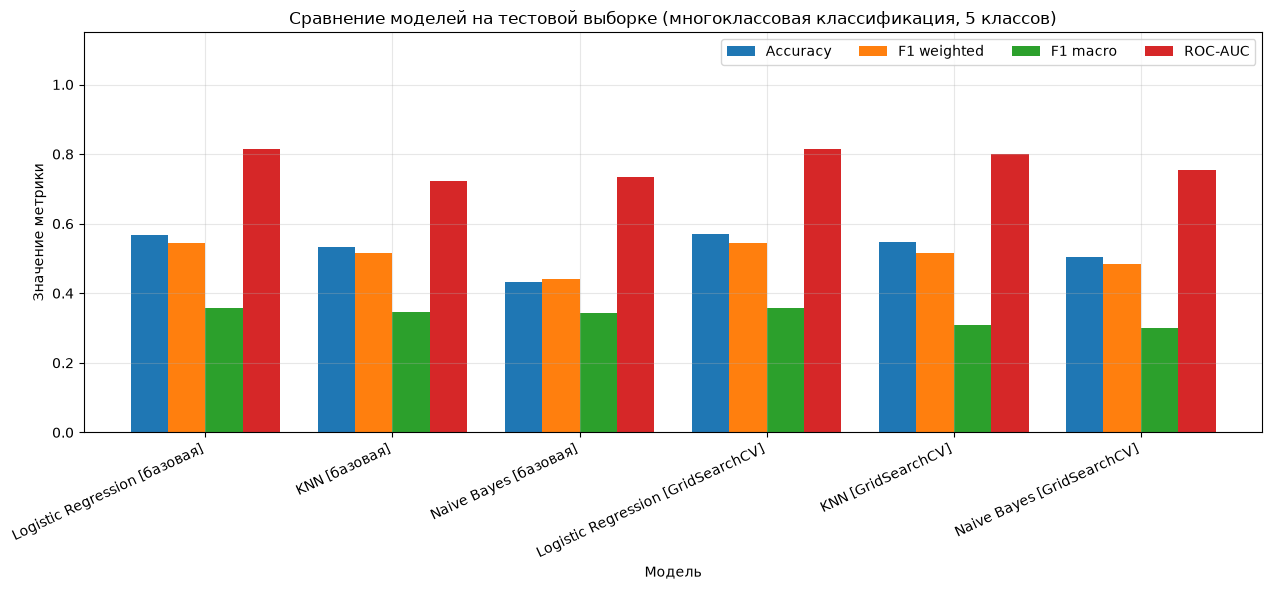

In [17]:
# bar plot: сравнение моделей по метрикам на тесте
metric_cols = ['Accuracy', 'F1 weighted', 'F1 macro', 'ROC-AUC']
ax = summary[metric_cols].plot(kind='bar', figsize=(13, 6), width=0.8)
ax.set_title('Сравнение моделей на тестовой выборке (многоклассовая классификация, 5 классов)')
ax.set_xlabel('Модель')
ax.set_ylabel('Значение метрики')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', ncol=4)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [18]:
# выбор лучшей модели по CV F1 weighted среди настроенных моделей
tuned_cv = {n: grids[n].best_score_ for n in grids}
best_name = max(tuned_cv, key=tuned_cv.get)
best_pipe = tuned_pipes[best_name]
print('CV F1 weighted настроенных моделей:', {k: round(v, 4) for k, v in tuned_cv.items()})
print('Лучшая модель:', best_name)
print('Параметры:', grids[best_name].best_params_)
print('Метрики на test:', {k: round(v, 4) for k, v in tuned_test[best_name].items()})

CV F1 weighted настроенных моделей: {'Logistic Regression': np.float64(0.5117), 'KNN': np.float64(0.5094), 'Naive Bayes': np.float64(0.4742)}
Лучшая модель: Logistic Regression
Параметры: {'model__C': 100.0}
Метрики на test: {'Accuracy': 0.5695, 'F1 weighted': 0.5443, 'F1 macro': 0.3569, 'ROC-AUC': 0.8147}


**Интерпретация и выбор лучшей модели.** По кросс-валидации лучшей оказалась **логистическая регрессия (C = 100)**: CV F1 weighted 0.512; на тесте accuracy 0.570, F1 weighted 0.544, F1 macro 0.357, ROC-AUC 0.815. KNN после подбора почти не уступает в CV (0.509), но на тесте заметно слабее по F1 weighted (0.516 против 0.544) и по F1 macro (0.308 против 0.357). Наивный Байес стал лучше (0.484 на тесте), но остаётся последним.

Разница между LR и KNN в CV (0.002) много меньше стандартного отклонения по фолдам, то есть статистически модели неразличимы. В пользу логистической регрессии: выше качество на тесте и ROC-AUC, она быстрее, проще, и её коэффициенты можно интерпретировать. Подбор гиперпараметров дал небольшой прирост: +0.004 у LR, +0.020 у KNN и +0.05 у NB по CV. Уровень качества определяется скорее признаками и перекрытием классов, чем настройкой моделей.

## 11. Анализ лучшей модели

### 11.1 Важность признаков

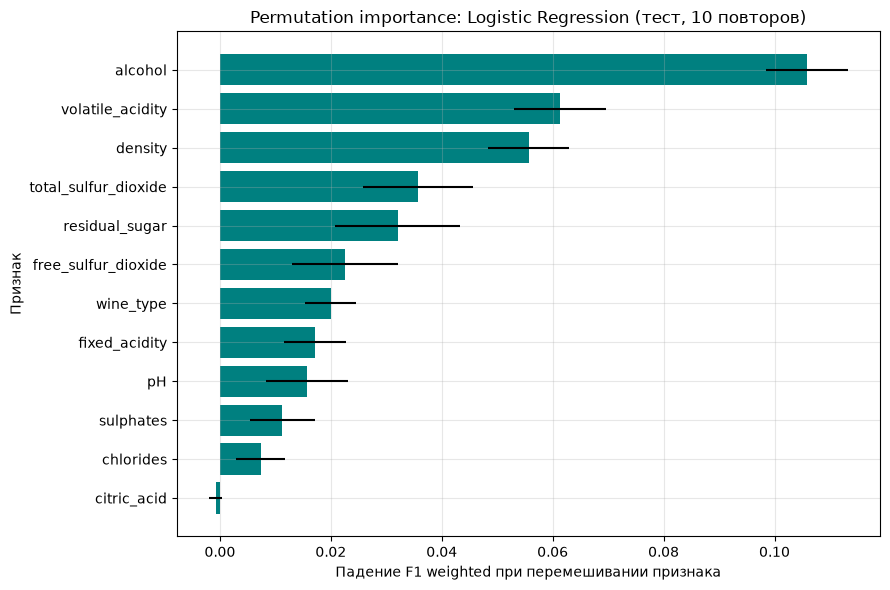

                        mean     std
alcohol               0.1059  0.0074
volatile_acidity      0.0614  0.0083
density               0.0557  0.0073
total_sulfur_dioxide  0.0357  0.0099
residual_sugar        0.0321  0.0113
free_sulfur_dioxide   0.0226  0.0096
wine_type             0.0200  0.0046
fixed_acidity         0.0172  0.0056
pH                    0.0156  0.0074
sulphates             0.0112  0.0058
chlorides             0.0073  0.0045
citric_acid          -0.0008  0.0012


In [19]:
# Permutation importance: на сколько падает F1 weighted, если перемешать значения признака на тесте.
# Считаем по исходным колонкам (новые признаки пересчитываются внутри пайплайна из них).
perm = permutation_importance(best_pipe, X_test, y_test, scoring='f1_weighted',
                              n_repeats=10, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                       index=X_test.columns).sort_values('mean')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(perm_df.index, perm_df['mean'], xerr=perm_df['std'], color='teal')
ax.set_title(f'Permutation importance: {best_name} (тест, 10 повторов)')
ax.set_xlabel('Падение F1 weighted при перемешивании признака')
ax.set_ylabel('Признак')
plt.tight_layout()
plt.show()
print(perm_df.sort_values('mean', ascending=False).round(4))

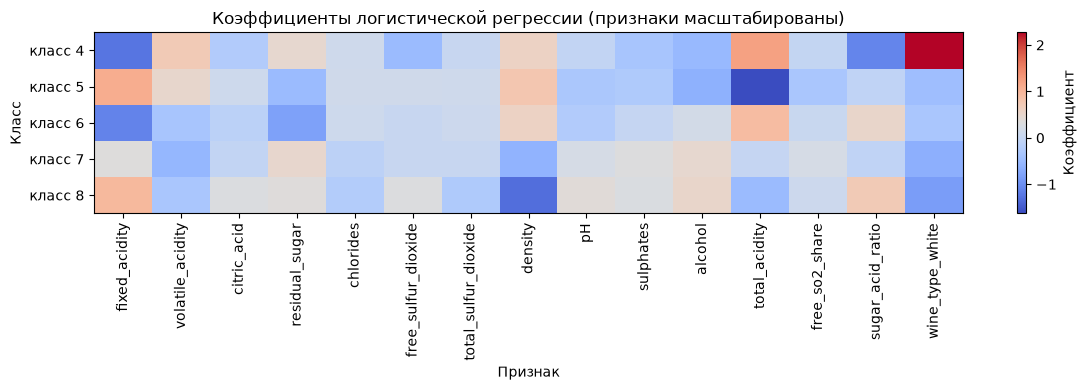

In [20]:
# если лучшая модель линейная — дополнительно смотрим коэффициенты
final_model = best_pipe.named_steps['model']
if hasattr(final_model, 'coef_'):
    coef = pd.DataFrame(final_model.coef_, index=[f'класс {c}' for c in final_model.classes_],
                        columns=feature_names)
    fig, ax = plt.subplots(figsize=(12, 4))
    im = ax.imshow(coef.values, cmap='coolwarm', aspect='auto')
    ax.set_xticks(range(coef.shape[1]))
    ax.set_xticklabels(coef.columns, rotation=90)
    ax.set_yticks(range(coef.shape[0]))
    ax.set_yticklabels(coef.index)
    ax.set_title('Коэффициенты логистической регрессии (признаки масштабированы)')
    ax.set_xlabel('Признак')
    ax.set_ylabel('Класс')
    ax.grid(False)
    plt.colorbar(im, ax=ax, label='Коэффициент')
    plt.tight_layout()
    plt.show()
else:
    print('У выбранной модели нет коэффициентов (feature_importances_/coef_), '
          'поэтому важность оценена только через permutation importance.')

**Интерпретация.** Самый важный признак — **`alcohol`**: его перемешивание снижает F1 weighted на 0.106. Далее идут `volatile_acidity` (0.061), `density` (0.056), `total_sulfur_dioxide` (0.036), `residual_sugar` (0.032), `free_sulfur_dioxide` (0.023) и тип вина (0.020). Вклад `citric_acid` практически нулевой, `chlorides` — малый (0.007). Порядок согласуется с корреляциями из EDA и с химическим смыслом: более крепкие вина с низкой летучей кислотностью оцениваются выше. Оговорка: у коррелированных признаков (`density`, `alcohol`, `residual_sugar`) важность «размазывается», поэтому по отдельности она может быть занижена. Тепловая карта коэффициентов показывает те же закономерности по классам: для классов 4 и 5 коэффициенты алкоголя отрицательные (−0.53 и −0.63), а летучей кислотности положительные (+0.71 и +0.50); для классов 7 и 8 — наоборот (алкоголь +0.47 и +0.51).

### 11.2 ROC-кривые (one-vs-rest)

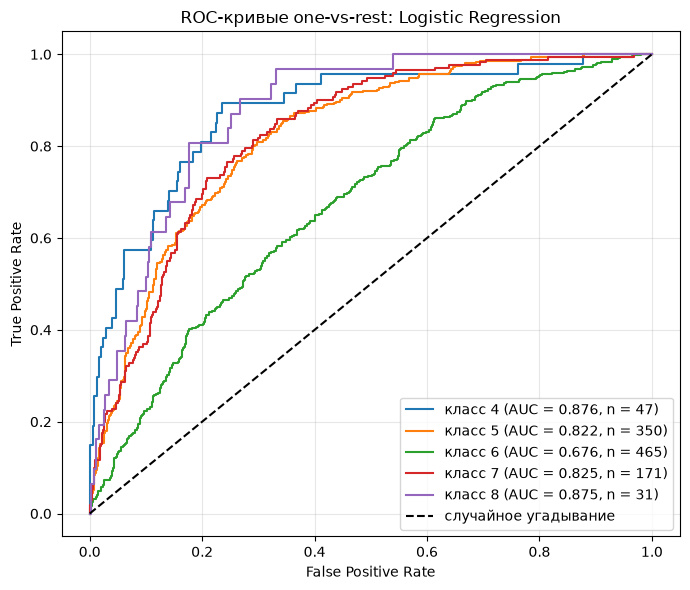

In [21]:
y_pred = best_pipe.predict(X_test)
proba = best_pipe.predict_proba(X_test)
classes = best_pipe.classes_
y_test_bin = label_binarize(y_test, classes=classes)

fig, ax = plt.subplots(figsize=(7, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, label=f'класс {c} (AUC = {auc(fpr, tpr):.3f}, n = {y_test_bin[:, i].sum()})')
ax.plot([0, 1], [0, 1], 'k--', label='случайное угадывание')
ax.set_title(f'ROC-кривые one-vs-rest: {best_name}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Интерпретация.** AUC по классам: 0.876 (класс 4), 0.822 (5), 0.676 (6), 0.825 (7), 0.875 (8). Модель хорошо ранжирует по вероятностям крайние классы (хуже/лучше обычного вина), но почти не может выделить среднюю оценку 6: она «окружена» соседями с похожим химическим составом. При этом высокий AUC у классов 4 и 8 не означает хороших предсказаний: при выборе класса по максимальной вероятности такие объекты проигрывают более частым классам (см. ниже). Значит, для редких классов нужен другой порог принятия решения, а не другой алгоритм ранжирования.

### 11.3 Анализ ошибок

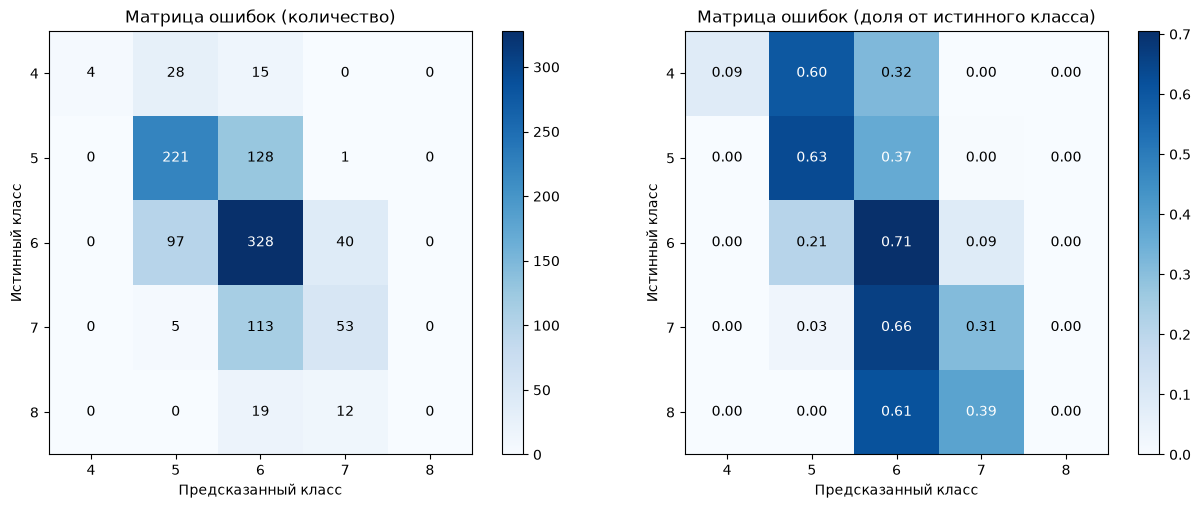

              precision  recall  f1-score  support
4                 1.000   0.085     0.157    47.00
5                 0.630   0.631     0.631   350.00
6                 0.544   0.705     0.614   465.00
7                 0.500   0.310     0.383   171.00
8                 0.000   0.000     0.000    31.00
accuracy          0.570   0.570     0.570     0.57
macro avg         0.535   0.346     0.357  1064.00
weighted avg      0.569   0.570     0.544  1064.00

Размер ошибки |предсказанный - истинный класс|, доля объектов:
0    0.570
1    0.393
2    0.038
Name: proportion, dtype: float64


In [22]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mat, title, fmt in [(axes[0], cm, 'Матрица ошибок (количество)', '{:d}'),
                            (axes[1], cm_norm, 'Матрица ошибок (доля от истинного класса)', '{:.2f}')]:
    im = ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(classes)):
        for j in range(len(classes)):
            color = 'white' if mat[i, j] > mat.max() / 2 else 'black'
            ax.text(j, i, fmt.format(mat[i, j]), ha='center', va='center', color=color)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
print(report.round(3))

# насколько «далеко» ошибается модель (классы упорядочены)
dist = np.abs(y_pred - y_test.values)
print('\nРазмер ошибки |предсказанный - истинный класс|, доля объектов:')
print(pd.Series(dist).value_counts(normalize=True).sort_index().round(3))

Accuracy по типу вина:
wine_type
red      0.608
white    0.557
Name: correct, dtype: float64

Отклонение среднего значения признака от среднего по train (в std):
         alcohol  volatile_acidity  density  residual_sugar  chlorides  \
correct                                                                  
False      0.111            -0.060   -0.119          -0.067     -0.048   
True      -0.081             0.055    0.037           0.060      0.047   

         total_sulfur_dioxide  
correct                        
False                    0.01  
True                     0.04  

Доля верных предсказаний по истинным классам:
      доля верных  объектов
true                       
4           0.085        47
5           0.631       350
6           0.705       465
7           0.310       171
8           0.000        31


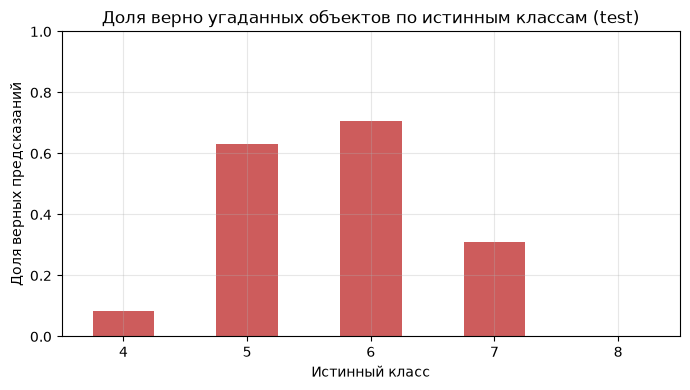


Самые уверенные ошибки модели:
     wine_type  alcohol  volatile_acidity  density  true  pred  confidence
162        red      9.3             0.620    0.997     6     5       0.803
16         red      9.0             0.590    0.997     4     5       0.791
140        red      9.3             0.600    0.997     6     5       0.774
2230     white      9.1             0.640    0.998     4     5       0.755
1035       red      9.5             0.570    0.997     6     5       0.747
2226     white      9.3             0.600    0.997     4     5       0.733
385        red     11.2             0.685    1.003     7     5       0.727
638        red      9.3             0.590    1.000     6     5       0.723


In [23]:
# профиль правильно и неправильно классифицированных объектов
err = X_test.copy()
err['true'] = y_test.values
err['pred'] = y_pred
err['correct'] = err['true'] == err['pred']
err['confidence'] = proba.max(axis=1)

# точность по типу вина
print('Accuracy по типу вина:')
print(err.groupby('wine_type')['correct'].mean().round(3))

# сравнение средних значений ключевых признаков (в единицах стандартного отклонения train)
key_cols = ['alcohol', 'volatile_acidity', 'density', 'residual_sugar', 'chlorides', 'total_sulfur_dioxide']
std_tr = X_train[key_cols].std()
profile = (err.groupby('correct')[key_cols].mean() - X_train[key_cols].mean()) / std_tr
print('\nОтклонение среднего значения признака от среднего по train (в std):')
print(profile.round(3))

# доля ошибок по классам
err_by_class = err.groupby('true')['correct'].agg(['mean', 'count'])
err_by_class.columns = ['доля верных', 'объектов']
print('\nДоля верных предсказаний по истинным классам:')
print(err_by_class.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
err_by_class['доля верных'].plot(kind='bar', ax=ax, color='indianred')
ax.set_title('Доля верно угаданных объектов по истинным классам (test)')
ax.set_xlabel('Истинный класс')
ax.set_ylabel('Доля верных предсказаний')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# самые «уверенные» ошибки модели
worst = err[~err['correct']].sort_values('confidence', ascending=False).head(8)
print('\nСамые уверенные ошибки модели:')
print(worst[['wine_type', 'alcohol', 'volatile_acidity', 'density', 'true', 'pred', 'confidence']].round(3))

**Интерпретация.**
* Доля верных ответов — 57 %. Все остальные ошибки почти целиком «соседние»: 39.3 % объектов отнесены к соседнему классу, 3.8 % — через один класс, ошибок на 3 и более класса нет. Модель понимает общий порядок качества, но не различает близкие оценки.
* Хуже всего предсказываются **редкие классы**: класс 4 (recall 0.085: найдено 4 из 47, но precision = 1.0) и класс 8 (recall 0: ни одного верного из 31; 61 % таких вин отнесено к классу 6, 39 % — к классу 7). Класс 7 тоже плох (recall 0.31: 113 из 171 вин ушло в класс 6). Модель предсказывает в основном классы 5 и 6.
* Красные вина предсказываются немного лучше белых (accuracy 0.608 и 0.557).
* Средние значения признаков у верных и неверных объектов различаются мало (не более 0.12 стандартных отклонения): ошибки не связаны с выбросами, это объекты в области перекрытия классов.
* Самые уверенные ошибки — вина с низким алкоголем (9.0–9.5 %), повышенной летучей кислотностью (0.57–0.64) и плотностью ≈ 0.997, которые по химии похожи на «типичные пятёрки», но получили оценку 6 или 4. Это шум в разметке: оценки дали дегустаторы, и субъективность нельзя убрать никакой моделью по химическому составу.

### 11.4 Устойчивость: кривая обучения

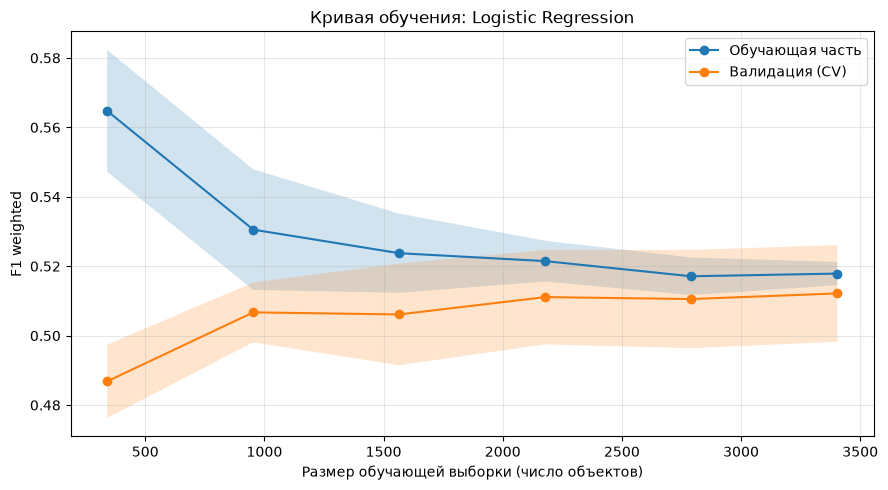

 размер train  train F1  CV F1
          340    0.5648 0.4868
          953    0.5305 0.5067
         1565    0.5238 0.5061
         2178    0.5215 0.5111
         2791    0.5171 0.5105
         3404    0.5179 0.5122


In [24]:
# кривая обучения: качество на обучающей и валидационной частях при росте размера train
sizes, tr_scores, va_scores = learning_curve(
    clone(best_pipe), X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 6),
    cv=cv, scoring='f1_weighted', shuffle=True, random_state=SEED, n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(sizes, tr_scores.mean(axis=1), 'o-', label='Обучающая часть')
plt.fill_between(sizes, tr_scores.mean(axis=1) - tr_scores.std(axis=1),
                 tr_scores.mean(axis=1) + tr_scores.std(axis=1), alpha=0.2)
plt.plot(sizes, va_scores.mean(axis=1), 'o-', label='Валидация (CV)')
plt.fill_between(sizes, va_scores.mean(axis=1) - va_scores.std(axis=1),
                 va_scores.mean(axis=1) + va_scores.std(axis=1), alpha=0.2)
plt.xlabel('Размер обучающей выборки (число объектов)')
plt.ylabel('F1 weighted')
plt.title(f'Кривая обучения: {best_name}')
plt.legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame({'размер train': sizes, 'train F1': tr_scores.mean(axis=1).round(4),
                    'CV F1': va_scores.mean(axis=1).round(4)}).to_string(index=False))

**Интерпретация.** При росте выборки с 340 до 3404 объектов качество на обучающей части падает (0.565 → 0.518), а на валидации растёт (0.487 → 0.512); к концу кривые практически сходятся (разрыв ≈ 0.006). Это типичная картина **недообучения (высокого смещения)**: модель слишком проста для данных. Валидационная кривая выходит на плато уже примерно при 2000 объектах, то есть простое добавление таких же данных почти ничего не даст. Чтобы улучшить результат, нужны более выразительные модели (нелинейные взаимодействия), новые признаки либо другая постановка задачи. Переобучения нет, это согласуется с близостью CV и теста.

### 11.5 Устойчивость: работа с несбалансированными классами

Классы 5 и 6 составляют основную часть данных, а классы 4 и 8 редкие. Проверим, помогает ли взвешивание классов: логистическая регрессия с `class_weight='balanced'` (веса обратно пропорциональны частоте классов) против обычной.

                                Accuracy (test)  F1 weighted (test)  \
Модель                                                                
LogReg (по умолчанию)                    0.5686              0.5433   
LogReg (class_weight=balanced)           0.4098              0.4384   

                                F1 macro (test)  CV F1 weighted  CV F1 macro  
Модель                                                                        
LogReg (по умолчанию)                    0.3564          0.5078       0.3099  
LogReg (class_weight=balanced)           0.3555          0.3992       0.3167  

Полнота (recall) по классам на test:
         LogReg (по умолчанию)  LogReg (class_weight=balanced)
класс 4                  0.085                           0.702
класс 5                  0.629                           0.526
класс 6                  0.705                           0.312
класс 7                  0.310                           0.310
класс 8                  0.000                

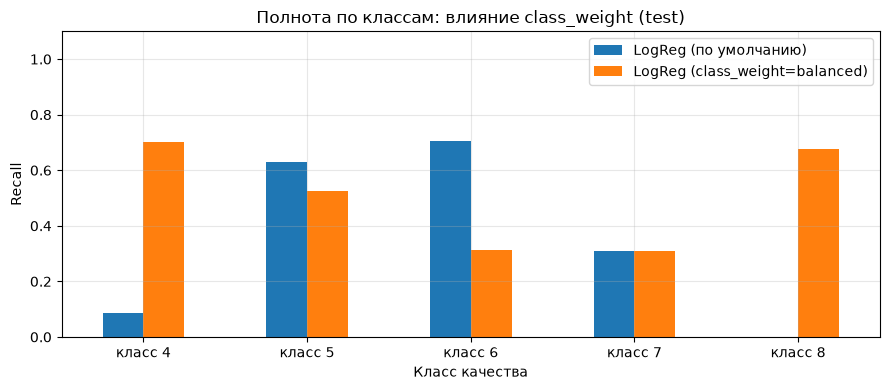

In [25]:
imb_models = {
    'LogReg (по умолчанию)': LogisticRegression(max_iter=1000, random_state=SEED),
    'LogReg (class_weight=balanced)': LogisticRegression(max_iter=1000, random_state=SEED,
                                                         class_weight='balanced'),
}
imb_rows = []
recalls = {}
for name, model in imb_models.items():
    pipe = make_pipe(model).fit(X_train, y_train)
    m = evaluate(pipe, X_test, y_test)
    cvr = cross_validate(make_pipe(model), X_train, y_train, cv=cv,
                         scoring={'f1w': 'f1_weighted', 'f1m': 'f1_macro'})
    imb_rows.append({'Модель': name, 'Accuracy (test)': m['Accuracy'],
                     'F1 weighted (test)': m['F1 weighted'], 'F1 macro (test)': m['F1 macro'],
                     'CV F1 weighted': cvr['test_f1w'].mean(), 'CV F1 macro': cvr['test_f1m'].mean()})
    recalls[name] = recall_score(y_test, pipe.predict(X_test), average=None, labels=pipe.classes_)

print(pd.DataFrame(imb_rows).set_index('Модель').round(4))
rec_df = pd.DataFrame(recalls, index=[f'класс {c}' for c in classes])
print('\nПолнота (recall) по классам на test:')
print(rec_df.round(3))

ax = rec_df.plot(kind='bar', figsize=(9, 4))
ax.set_title('Полнота по классам: влияние class_weight (test)')
ax.set_xlabel('Класс качества')
ax.set_ylabel('Recall')
ax.set_ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Интерпретация.** Взвешивание классов резко повышает полноту редких классов: recall класса 4 вырастает с 0.085 до 0.702, класса 8 — с 0 до 0.677. Но плата за это велика: recall самого частого класса 6 падает с 0.705 до 0.312, accuracy — с 0.569 до 0.410, F1 weighted — с 0.543 до 0.438. F1 macro при этом почти не меняется (0.356 и 0.356 на тесте; в CV 0.310 и 0.317). Следовательно, взвешивание не устраняет ошибки, а лишь перераспределяет их: классы на самом деле перекрываются в пространстве признаков. Выбор режима зависит от цены ошибки: если важно не пропустить очень плохие или выдающиеся вина, подходит `class_weight='balanced'` (или сдвиг порога), если важна общая точность — модель по умолчанию.

## 12. Бонус: самостоятельное расширение

### 12.1 Гипотезы

**Гипотеза 1 (семейство моделей).** Связь химических показателей с качеством вина нелинейная и содержит взаимодействия признаков (например, алкоголь × плотность × сахар). Линейная модель, KNN и наивный Байес (с предположением о независимости признаков) этого не улавливают. Поэтому ансамбли деревьев — случайный лес (`RandomForestClassifier`) и градиентный бустинг (`HistGradientBoostingClassifier`) — должны заметно превзойти базовые модели по F1.

**Гипотеза 2 (абляция признаков).**  
а) Признак `alcohol` — самый сильный предиктор (по корреляции и важности), поэтому его удаление должно дать самое заметное падение качества.  
б) Три созданных признака являются комбинациями уже имеющихся, поэтому для деревьев и сложных моделей они почти ничего не добавят, а выигрыш возможен только у простых (линейных) моделей.

Оцениваем по кросс-валидации на train (cv = 5), на тесте — только для итоговой отчётности.

                                                    Accuracy  F1 weighted  \
Модель                                                                      
Random Forest                                         0.5930       0.5694   
HistGradientBoosting                                  0.5555       0.5420   
Logistic Regression [GridSearchCV] (лучшая из о...    0.5695       0.5443   

                                                    F1 macro  ROC-AUC  \
Модель                                                                  
Random Forest                                         0.3835   0.8312   
HistGradientBoosting                                  0.3888   0.8037   
Logistic Regression [GridSearchCV] (лучшая из о...    0.3569   0.8147   

                                                    CV F1 weighted (mean)  \
Модель                                                                      
Random Forest                                                      0.5448   
HistGradientBoost

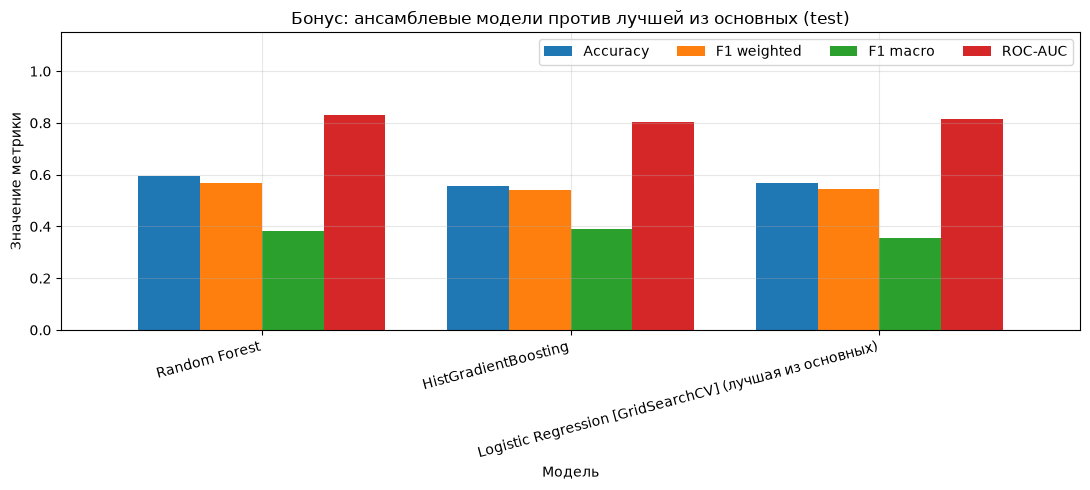

In [26]:
# --- 12.2 Дополнительные модели ---
bonus_models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=SEED),
}
bonus_rows = []
bonus_pipes = {}
for name, model in bonus_models.items():
    pipe = make_pipe(model).fit(X_train, y_train)
    bonus_pipes[name] = pipe
    m = evaluate(pipe, X_test, y_test)
    cvr = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=cv_scoring)
    row = {'Модель': name}
    row.update(m)
    row['CV F1 weighted (mean)'] = cvr['test_f1_weighted'].mean()
    row['CV F1 weighted (std)'] = cvr['test_f1_weighted'].std()
    bonus_rows.append(row)

# для сравнения добавляем лучшую настроенную модель из основной части
row = {'Модель': f'{best_name} [GridSearchCV] (лучшая из основных)'}
row.update(tuned_test[best_name])
row['CV F1 weighted (mean)'] = grids[best_name].best_score_
row['CV F1 weighted (std)'] = grids[best_name].cv_results_['std_test_score'][grids[best_name].best_index_]
bonus_rows.append(row)

bonus_df = pd.DataFrame(bonus_rows).set_index('Модель')
print(bonus_df.round(4))

ax = bonus_df[['Accuracy', 'F1 weighted', 'F1 macro', 'ROC-AUC']].plot(kind='bar', figsize=(11, 5), width=0.8)
ax.set_title('Бонус: ансамблевые модели против лучшей из основных (test)')
ax.set_xlabel('Модель')
ax.set_ylabel('Значение метрики')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', ncol=4)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

                               Модель     Набор признаков  CV F1 weighted  CV std  CV F1 macro  Test F1 weighted  Δ CV F1 vs все
Logistic Regression (лучшая основная)        Все признаки          0.5117  0.0153       0.3210            0.5443          0.0000
Logistic Regression (лучшая основная) Без новых признаков          0.5114  0.0221       0.3194            0.5440         -0.0003
Logistic Regression (лучшая основная)         Без alcohol          0.5002  0.0171       0.3147            0.5345         -0.0114
Logistic Regression (лучшая основная)       Без wine_type          0.5095  0.0167       0.3097            0.5293         -0.0022
                        Random Forest        Все признаки          0.5448  0.0226       0.3600            0.5694          0.0000
                        Random Forest Без новых признаков          0.5439  0.0181       0.3547            0.5768         -0.0009
                        Random Forest         Без alcohol          0.5354  0.0236       0.3451   

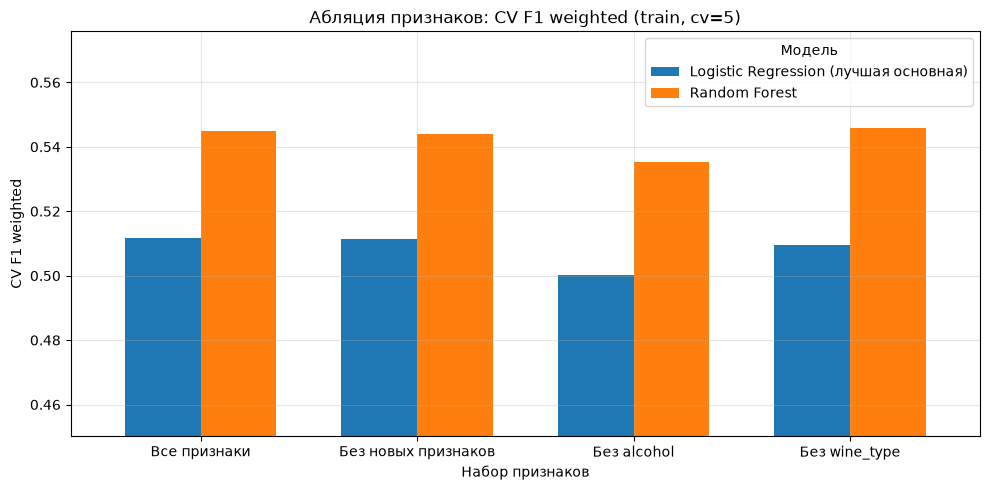

In [27]:
# --- 12.3 Абляция признаков ---
ablation_sets = {
    'Все признаки': (numeric_cols, categorical_cols),
    'Без новых признаков': (BASE_NUMERIC, categorical_cols),
    'Без alcohol': ([c for c in numeric_cols if c != 'alcohol'], categorical_cols),
    'Без wine_type': (numeric_cols, []),
}
ablation_models = {
    f'{best_name} (лучшая основная)': best_pipe.named_steps['model'],
    'Random Forest': bonus_models['Random Forest'],
}

abl_rows = []
for mname, model in ablation_models.items():
    for setname, (num_c, cat_c) in ablation_sets.items():
        def make_abl_pipe():
            return Pipeline(steps=[('prep', build_preprocessor(num_c, cat_c)), ('model', clone(model))])
        cvr = cross_validate(make_abl_pipe(), X_train, y_train, cv=cv,
                             scoring={'f1w': 'f1_weighted', 'f1m': 'f1_macro'})
        fitted = make_abl_pipe().fit(X_train, y_train)
        test_f1 = f1_score(y_test, fitted.predict(X_test), average='weighted')
        abl_rows.append({'Модель': mname, 'Набор признаков': setname,
                         'CV F1 weighted': cvr['test_f1w'].mean(),
                         'CV std': cvr['test_f1w'].std(),
                         'CV F1 macro': cvr['test_f1m'].mean(),
                         'Test F1 weighted': test_f1})

abl_df = pd.DataFrame(abl_rows)
# изменение относительно полного набора признаков
base_cv = abl_df[abl_df['Набор признаков'] == 'Все признаки'].set_index('Модель')['CV F1 weighted']
abl_df['Δ CV F1 vs все'] = abl_df.apply(lambda r: r['CV F1 weighted'] - base_cv[r['Модель']], axis=1)
print(abl_df.round(4).to_string(index=False))

pivot = abl_df.pivot(index='Набор признаков', columns='Модель', values='CV F1 weighted')
pivot = pivot.loc[list(ablation_sets.keys())]
ax = pivot.plot(kind='bar', figsize=(10, 5), width=0.7)
ax.set_title('Абляция признаков: CV F1 weighted (train, cv=5)')
ax.set_xlabel('Набор признаков')
ax.set_ylabel('CV F1 weighted')
ax.set_ylim(max(0, pivot.values.min() - 0.05), pivot.values.max() + 0.03)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Итоги бонусного эксперимента.**

*Гипотеза 1 (ансамбли лучше базовых моделей) — подтверждена частично.* Случайный лес — лучшая из всех моделей: на тесте accuracy 0.593, F1 weighted 0.569, F1 macro 0.384, ROC-AUC 0.831; CV F1 weighted 0.545 ± 0.023 против 0.512 у лучшей основной модели (+0.033 в CV, +0.025 на тесте). Градиентный бустинг (с параметрами по умолчанию, без подбора) выигрывает в CV (0.534) и по F1 macro (0.389), но на тесте по F1 weighted равен логистической регрессии (0.542 и 0.544), а по ROC-AUC уступает (0.804 и 0.815). Прирост ансамблей небольшой и сопоставим с разбросом по фолдам (≈ 0.02); он подтверждает наличие нелинейных зависимостей, но не снимает основную проблему перекрытия классов.

*Гипотеза 2а (`alcohol` — самый важный признак) — подтверждена по порядку, но эффект мал.* Удаление `alcohol` даёт самое большое падение CV F1: −0.011 у LR и −0.009 у случайного леса (на тесте −0.010 и −0.015). Эффект небольшой, потому что алкоголь частично заменяется `density` (r = −0.66) и `residual_sugar`.

*Гипотеза 2б (новые признаки почти ничего не добавляют) — подтверждена.* Без трёх новых признаков качество практически то же (−0.0003 у LR, −0.0009 у леса при std 0.015–0.022). Причина видна в матрице корреляций: `total_acidity` и `sugar_acid_ratio` почти совпадают с исходными признаками (r = 0.99 и 0.98). Удаление `wine_type` тоже в пределах шума (−0.002 у LR, +0.001 у леса в CV).

Для честности: все выводы по бонусу сделаны по кросс-валидации на train, тест использован только для отчёта.

## 13. Выводы

### 13.1 Краткие выводы по этапам

1. **Данные.** 6497 образцов, 11 химических признаков и тип вина; пропусков нет, найдено 1177 дубликатов (удалены до разбиения, чтобы одни и те же объекты не попали и в train, и в test). Оценки 3 и 9 объединены с соседними (4 и 8), получилось 5 упорядоченных классов с сильным дисбалансом (4.4 / 32.9 / 43.7 / 16.1 / 2.9 %).
2. **Предобработка без утечки.** Новые признаки, обрезка выбросов, импутация, масштабирование и one-hot оформлены как sklearn-пайплайн; `fit` — только на train, к test применяется `transform`, кросс-валидация и GridSearchCV запускаются над всем пайплайном.
3. **EDA.** Качество связано в первую очередь с алкоголем (r = +0.46), затем с плотностью (−0.32), летучей кислотностью (−0.26) и хлоридами (−0.19). Многие признаки коррелированы между собой. Тип вина влияет слабо (V Крамера 0.127). Выбросы обработаны винзоризацией по IQR (k = 3).
4. **Модели.** Три модели обучены на одном разбиении. Логистическая регрессия: F1 weighted 0.543, KNN: 0.516, наивный Байес: 0.440; кросс-валидация (cv = 5) подтверждает порядок моделей.
5. **GridSearchCV (3 комбинации на модель).** После подбора: LR 0.512, KNN 0.509, NB 0.474 (CV F1 weighted). Лучшая модель — логистическая регрессия (C = 100): на тесте accuracy 0.570, F1 weighted 0.544, F1 macro 0.357, ROC-AUC 0.815.
6. **Анализ.** Важнее всего `alcohol`, затем `volatile_acidity` и `density`. Ошибки в основном соседние (39 % на один класс, 3.8 % на два), редкие классы 4 и 8 практически не распознаются (recall 0.085 и 0). Кривая обучения указывает на недообучение. Взвешивание классов лишь перераспределяет ошибки.
7. **Бонус.** Случайный лес лучше всех (CV 0.545, test 0.569), но выигрыш небольшой; `alcohol` — самый значимый признак по абляции; созданные признаки ничего не добавили.

### 13.2 Ответы на вопросы

**Какие особенности данных повлияли на качество моделей?**
Три фактора: (1) сильный дисбаланс классов — модели предсказывают в основном классы 5 и 6; (2) перекрытие классов: соседние оценки почти неотличимы по химическому составу, а оценка получена из субъективной дегустации; (3) коррелированные признаки (`alcohol`–`density`, свободный и общий SO₂, кислотности), которые вредят наивному Байесу и делят важность между собой. Кроме того, влияние отдельных признаков на оценку умеренное (|r| ≤ 0.46).

**Какая модель показала лучшие результаты и почему?**
Из трёх обязательных моделей — логистическая регрессия (CV F1 weighted 0.512, на тесте 0.544, ROC-AUC 0.815). Она лучше справляется с гладкими, почти линейными зависимостями (алкоголь ↑ — качество ↑), устойчива к шуму и не склонна к переобучению на перекрывающихся классах. KNN в CV сопоставим, но хуже на тесте; наивный Байес проигрывает из-за нарушения допущения о независимости признаков. Из всех экспериментов лучший — случайный лес (F1 weighted 0.569 на тесте), так как улавливает нелинейности и взаимодействия.

**Какие ограничения имеют полученные результаты?**
* Качество умеренное: accuracy около 0.57 при доле главного класса 0.44.
* Метки субъективны (оценка дегустаторов), поэтому существует «потолок» качества, который не зависит от модели.
* Данные относятся к одному региону и одному типу вина (португальское Vinho Verde); перенос на другие вина не гарантирован. Нет сведений о сорте винограда, годе урожая, производителе.
* Классы 3 и 9 пришлось объединить с соседними; для классов 4 и 8 в тесте всего 47 и 31 объект, поэтому метрики по ним неустойчивы.
* Одно разбиение train/test даёт оценку с разбросом (std по фолдам ≈ 0.015–0.025); разницу в 0.01–0.02 между моделями нельзя считать значимой.
* Удалены 1177 дубликатов: часть реальных «одинаковых» вин потеряна, но оценка стала честнее.

**Как можно улучшить качество модели в будущем?**
* Использовать ординальную классификацию или регрессию с округлением (учитывать порядок классов) и метрики, штрафующие за размер ошибки.
* Подобрать гиперпараметры ансамблей (случайный лес, градиентный бустинг) и сравнить по повторной стратифицированной кросс-валидации.
* Для редких классов подобрать порог решения или веса классов под бизнес-цель; объединить классы в три группы (низкое / среднее / высокое).
* Добавить осмысленные признаки-взаимодействия (например, алкоголь × плотность, остаточный сахар относительно алкоголя) и убрать дублирующие (`total_acidity`, `sugar_acid_ratio`).
* Собрать больше данных по редким классам и дополнительные сведения (сорт, год, условия брожения).

### 13.3 Вопросы варианта 3: интерпретация классов и рекомендации

**Как интерпретировать полученные классы?**
Классы образуют упорядоченную шкалу, которая в основном определяется содержанием алкоголя и летучей кислотностью:
* **Класс 4 (оценка ≤ 4)** — дефектные вина: повышенная летучая кислотность (медиана 0.37 против 0.27–0.28 у классов 6–8) и низкий свободный SO₂ (медиана 15 против 27–31); алкоголь при этом не самый низкий (медиана 10.1 %), поэтому модель путает такие вина с классом 5.
* **Класс 5** — «рядовые» вина с самым низким алкоголем (медиана 9.6 %) и наибольшей плотностью (0.9960); хлориды выше, чем у более качественных классов (0.053).
* **Класс 6** — «середина»: умеренный алкоголь (10.5 %), низкая летучая кислотность; ближайшие по свойствам к обоим соседям, поэтому хуже всего ранжируются (AUC 0.676), но предсказываются лучше всего из-за размера класса.
* **Классы 7 и 8** — лучшие вина: высокий алкоголь (медианы 11.5 % и 12.1 %), низкая летучая кислотность (0.28), наименьшие плотность (0.9922 и 0.9917) и хлориды (0.039 и 0.035). Между собой они различаются слабо, и класс 8 (редкий) модель не распознаёт.

**Какие рекомендации можно дать на основе этих результатов?**
1. *Для производителей:* контролировать зрелость винограда и ферментацию так, чтобы получать достаточный алкоголь (в данных у лучших вин 11.5–12 %), и не допускать роста летучей кислотности (гигиена, контроль брожения): по данным именно эти показатели сильнее всего связаны с оценкой.
2. *Для контроля качества:* использовать модель как инструмент предварительного отбора, а не замену дегустации. Хорошо отсеиваются вина, похожие на «типичные пятёрки» и ниже; вина высшего класса модель не находит, их нужно оценивать вручную.
3. *Для работы с редкими классами:* если важно не пропустить дефектные или выдающиеся вина, использовать `class_weight='balanced'` или понизить порог принятия решения для классов 4 и 8 (AUC для них 0.88, то есть ранжирование хорошее) и принять рост числа ложных срабатываний.
4. *Для дальнейшей работы:* собрать дополнительные данные (сорт винограда, год, условия хранения), без которых различить соседние оценки по химии практически невозможно.